# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: The Pre-Publish Ethics Review

### Scenario

You're a junior analyst at **Northwind Retail Insights**. A colleague drafted a set of
charts for tomorrow's regional performance report, and your manager asked you to review
them before they go out. She's blunt about what she wants checked:

1. *"I can't tell what I'm supposed to look at first on any of these charts. There's no
   hierarchy."*
2. *"One of these charts will get someone using a grayscale office printer completely
   lost. Fix that before it ships."*
3. *"I saw a headline chart that made a tiny year-over-year change look like a crisis.
   Check the axis."*
4. *"Someone wrote 'this PROVES our new strategy is working' under a chart. That's not
   what a data label is for."*

You'll work through the same review a real analyst would: fix a hierarchy problem, make
a chart accessible, catch a scale exaggeration, and rewrite an overreaching annotation.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real sales data you'll be working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

sales = pd.read_csv("superstore.csv", encoding="latin-1")
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Year"] = sales["Order Date"].dt.year

print(f"Loaded {len(sales):,} orders, {sales.Year.min()}-{sales.Year.max()}.")
sales[["Order Date", "Region", "Product Category", "Sales", "Profit"]].head()

Loaded 8,399 orders, 2009-2012.


,Order Date,Region,Product Category,Sales,Profit
0,2010-10-13,Nunavut,Office Supplies,261.5400,-213.25
1,2012-10-01,Nunavut,Office Supplies,10123.0200,457.81
2,2012-10-01,Nunavut,Office Supplies,244.5700,46.71
3,2011-07-10,Nunavut,Technology,4965.7595,1198.97
4,2010-08-28,Nunavut,Office Supplies,394.2700,30.94


## Task 1 — Fix the Missing Hierarchy (Complaint #1)

**Real-world usage:** The manager can't tell what to look at first on the current
chart.

**Why this technique:** Visual hierarchy (size + weight + color) creates an
unmistakable primary -> secondary -> tertiary reading order without needing
instructions.

**TODO:** Build a figure with 3 text elements, using ONLY `fontsize`, `fontweight`, and
`color` to create hierarchy:
1. **Primary:** the region with the highest total profit, in large bold colored text.
2. **Secondary:** one supporting sentence, medium size, muted color.
3. **Tertiary:** a data-source footnote, small, light gray.

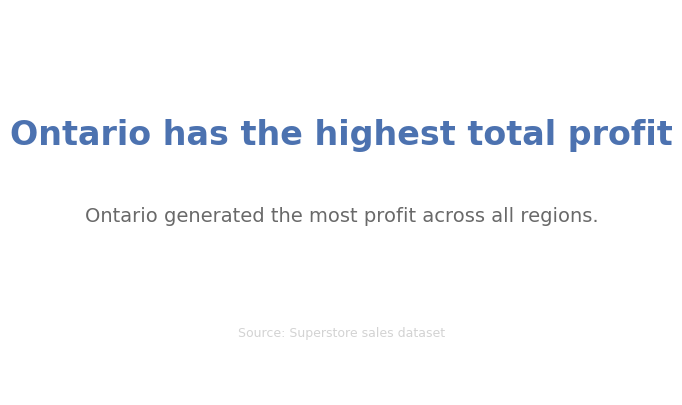

In [2]:
region_totals = sales.groupby("Region")["Profit"].sum().sort_values()
best_region = region_totals.idxmax()

fig, ax = plt.subplots(figsize=(7, 5))
ax.axis("off")

# TODO 1: primary element -- large, bold, colored
ax.text(
    0.5, 0.65,
    f"{best_region} has the highest total profit",
    ha="center",
    fontsize=24,
    fontweight="bold",
    color="#4C72B0"
)

# TODO 2: secondary element -- medium, muted color
ax.text(
    0.5, 0.45,
    f"{best_region} generated the most profit across all regions.",
    ha="center",
    fontsize=14,
    fontweight="normal",
    color="dimgray"
)

# TODO 3: tertiary element -- small, light gray
ax.text(
    0.5, 0.15,
    "Source: Superstore sales dataset",
    ha="center",
    fontsize=9,
    fontweight="normal",
    color="lightgray"
)

plt.show()

**Reflection:** Without reading any labels, in what order do your eyes land on the
three text elements? If someone glanced at this for only 2 seconds, what's the one
fact they'd walk away with?

_Your answer:_ | My eyes go to the large bold headline first, then the supporting sentence, and finally the small source note. If someone only looked at the figure for two seconds, the main fact they would notice is that Ontario has the highest total profit. The different font sizes, weights, and colors make the intended reading order clear.

## Task 2 — Make the Chart Accessible (Complaint #2)

**Real-world usage:** A colorblind or grayscale-printer viewer needs to be able to read
this chart too.

**Why this technique:** Redundant coding (color + pattern/shape) survives both
colorblindness and grayscale printing; color alone does not.

**TODO:**
1. Build a bar chart of total `Sales` by `Product Category`, one color per category.
2. Add a DIFFERENT hatch pattern per bar (`hatch="//"`, `"xx"`, `".."`) on top of the
   color, so the categories stay distinguishable if color is stripped away.
3. Add a legend showing category name.

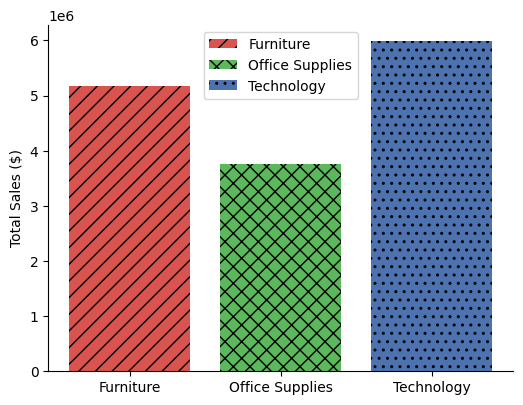

In [3]:
cat_sales = sales.groupby("Product Category")["Sales"].sum()

# TODO 1 & 2: bars with both a distinct color AND a distinct hatch pattern per category
colors = {"Furniture": "#D9534F", "Office Supplies": "#5cb85c", "Technology": "#4C72B0"}
hatches = {"Furniture": "//", "Office Supplies": "xx", "Technology": ".."}

fig, ax = plt.subplots(figsize=(6, 4.5))
for cat in cat_sales.index:
    ax.bar(
        cat,
        cat_sales[cat],
        color=colors[cat],
        hatch=hatches[cat],
        label=cat
    )  # TODO: plot one bar per category using colors[cat] and hatches[cat]

# TODO 3: legend
ax.legend()
ax.set_ylabel("Total Sales ($)")
plt.show()

**Reflection:** If you only used color (no hatch pattern), which two accessibility
failure modes from the lecture would this chart hit? Name both.

_Your answer:_ | Using only color could cause color-vision deficiency problems, making some categories difficult to distinguish. It could also fail when the chart is printed or viewed in grayscale, because the different colors may appear too similar. Using both color and hatch patterns provides a second visual cue and avoids these two accessibility issues.

## Task 3 — Catch the Axis Exaggeration (Complaint #3)

**Real-world usage:** A headline chart made a small real change look like a crisis.

**Why this technique:** Comparing the SAME data on a zero-baseline axis vs. a truncated
axis reveals exactly how much an axis choice is doing the "storytelling" instead of the
data.

**TODO:**
1. Compute total `Sales` by `Year`.
2. Compute the real percent change between the two most recent years.
3. Plot BOTH a zero-baseline version and a truncated-axis version, side by side, each
   titled with the real percent change.

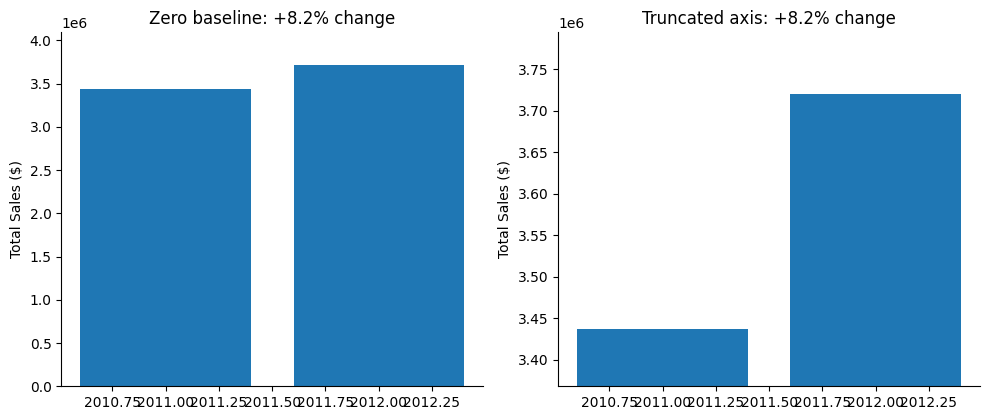

Real change from 2011 to 2012: +8.2%


In [4]:
yearly_sales = sales.groupby("Year")["Sales"].sum()

# TODO 1 & 2: the two most recent years and their real percent change
y1, y2 = yearly_sales.index[-2], yearly_sales.index[-1]
v1, v2 =  yearly_sales.loc[y1], yearly_sales.loc[y2]
pct_change = ((v2 - v1) / v1) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))

# TODO 3a: zero-baseline version (axes[0])
axes[0].bar([y1, y2], [v1, v2])
axes[0].set_ylim(0, max(v1, v2) * 1.1)
axes[0].set_title(f"Zero baseline: {pct_change:+.1f}% change")
axes[0].set_ylabel("Total Sales ($)")

# TODO 3b: truncated-axis version (axes[1]) -- pick tight y-limits close to v1/v2
axes[1].bar([y1, y2], [v1, v2])
axes[1].set_ylim(min(v1, v2) * 0.98, max(v1, v2) * 1.02)
axes[1].set_title(f"Truncated axis: {pct_change:+.1f}% change")
axes[1].set_ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

print(f"Real change from {y1} to {y2}: {pct_change:+.1f}%" if pct_change is not None else "Fill in pct_change above")

**Reflection:** Which of your two panels would you flag for the manager as
potentially misleading if it were used ALONE as the report's headline chart, with no
other context? Why?

_Your answer:_ | I would flag the truncated-axis panel as potentially misleading if it were used by itself. Because the y-axis starts close to the actual sales values instead of zero, the difference between the two years appears much larger than it really is. The real percentage change is relatively small, but the truncated scale can make it look dramatic. The zero-baseline chart gives a more accurate visual impression of the actual change.

## Task 4 — Rewrite the Overreaching Annotation (Complaint #4)

**Real-world usage:** A colleague's annotation claimed a chart "PROVES" a strategy is
working — language the data alone cannot support.

**Why this technique:** Distinguishing descriptive / interpretive / persuasive
annotation lets you keep useful interpretation while cutting unsupported claims.

**TODO:**
1. Given the overreaching annotation text below, write a DESCRIPTIVE version (states
   only the fact) and an INTERPRETIVE version (explains a plausible, appropriately
   hedged reason) — no causal "PROVES" language in either.
2. Plot the yearly sales trend with your INTERPRETIVE annotation on the most recent
   data point.

ORIGINAL (persuasive, overreaching): This PROVES our new strategy is working -- scale it up immediately
DESCRIPTIVE: Sales increased from the previous year to the most recent year.
INTERPRETIVE: The recent increase in sales may indicate that the new strategy is contributing to improved sales performance.


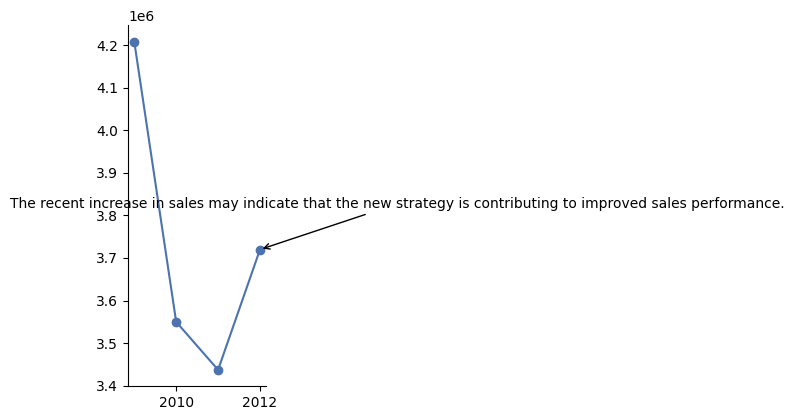

In [5]:
overreaching_original = "This PROVES our new strategy is working -- scale it up immediately"

# TODO 1: your rewrites
descriptive_version = "Sales increased from the previous year to the most recent year."
interpretive_version = "The recent increase in sales may indicate that the new strategy is contributing to improved sales performance."

print("ORIGINAL (persuasive, overreaching):", overreaching_original)
print("DESCRIPTIVE:", descriptive_version)
print("INTERPRETIVE:", interpretive_version)

# TODO 2: plot with your interpretive annotation on the last data point
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(yearly_sales.index, yearly_sales.values, "o-", color="#4C72B0")
# TODO: ax.annotate(...) using interpretive_version, pointing at the last year's value
ax.annotate(
    interpretive_version,
    xy=(yearly_sales.index[-1], yearly_sales.values[-1]),
    xytext=(-180, 30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()
plt.show()

**Reflection:** What specific evidence would you need (that this dataset alone
doesn't provide) before the ORIGINAL "proves it's working" claim would actually be
justified?

_Your answer:_ | I would need evidence from a controlled comparison showing that the strategy itself caused the increase in sales, such as a suitable control group or a well-designed before-and-after comparison. I would also need to rule out other factors such as seasonality, market changes, or other business decisions. Since this dataset only shows sales trends, it cannot establish causation on its own.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence sign-off note to your manager summarizing
this review. Your answer should:
- State which ONE of the four fixes above you consider the most urgent to ship before
  tomorrow, and why.
- Reference the lecture's 5-question Ethical Visualization Audit — pick one question
  from it and explain how it applies to Task 3 or Task 4 specifically.
- Name one guardrail (a review step, a style-guide rule, etc.) you'd recommend
  permanently adding to the team's process to prevent these four issues recurring.

_Your final recommendation here:_ | The most urgent fix is correcting the truncated axis because it can make a small change in sales appear much larger than it really is. The Ethical Visualization Audit question, “Could this visualization mislead the viewer?”, directly applies because the truncated-axis chart could create a misleading impression if viewed without context. For Task 4, the audit also reminds us to distinguish observed trends from claims about causation. I recommend adding a mandatory pre-publish ethics review using the five audit questions for every report. This would help the team catch misleading scales, accessibility issues, weak hierarchy, and overreaching claims before publication.